# 05 — Final Forecasting Model

**Project:** Sales Demand Forecasting & Anomaly Detection
**Dataset:** Corporación Favorita store sales (Kaggle) — daily network-level sales.

Phase 4 set the bar: the **seasonal naive** baseline reached **MAE ≈ $2.01M / MAPE ≈ 26%**
on the validation set. This phase builds a **real forecasting model** that beats that bar
by actually using the Phase-3 features (promo, holiday, calendar, lags, rolling stats).

We try **two families** and pick the winner on validation:

| Model family | Strengths | Weaknesses |
|---|---|---|
| **SARIMA** (statsmodels) | True time-series model; explicit weekly seasonality | Ignores promo/holiday inputs; needs smooth stationarity |
| **Tree-based ML** (Random Forest / Gradient Boosting) | Uses all Phase-3 features; captures interactions (promo x weekend) | Not a pure time-series model; needs careful lag handling |

> **statsmodels 0.15 installed successfully on Python 3.14** — so we can actually train both.

> **Interview focus:** the single most important idea is **forecasting framing**. We forecast
> *one day ahead* using only information known the day before. Every feature, split, and metric
> must respect that discipline — that is what separates an honest forecast from a leaky one.

## Setup — imports and data reload

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from statsmodels.tsa.statespace.sarimax import SARIMAX
import joblib

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")  # silence statsmodels estimation chatter

ROOT = Path(r"E:\Data Science\Sales Demand Forecasting and Anomaly Detection")
PROC = ROOT / "data" / "processed"

assert (PROC / "network_features.csv").exists(), \
    "Run 03_feature_engineering.ipynb first to produce the features."

df = pd.read_csv(PROC / "network_features.csv", parse_dates=["Date"])

train = df[df["split"] == "train"].copy().reset_index(drop=True)
valid = df[df["split"] == "validation"].copy().reset_index(drop=True)
test  = df[df["split"] == "test"].copy().reset_index(drop=True)

print(f"Train:      {len(train):>4d} rows  ({train['Date'].min().date()} to {train['Date'].max().date()})")
print(f"Validation: {len(valid):>4d} rows  ({valid['Date'].min().date()} to {valid['Date'].max().date()})")
print(f"Test:       {len(test):>4d} rows  ({test['Date'].min().date()} to {test['Date'].max().date()})")


Train:       911 rows  (2013-01-01 to 2015-06-30)
Validation:   15 rows  (2015-07-01 to 2015-07-15)
Test:         16 rows  (2015-07-16 to 2015-07-31)


---

# Part A — Same metrics, same bar

We reuse the exact metric functions and the **seasonal-naive bar** from Phase 4 so every
model is compared apples-to-apples. Baseline numbers to beat on **validation**:

- Seasonal naive: **MAE $2.011M** · RMSE $2.491M · **MAPE 25.9%**

In [2]:

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mape(y_true, y_pred):
    mask = y_true > 1000
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def evaluate(y_true, y_pred, label=""):
    return {
        "Model": label,
        "MAE ($m)": round(mae(y_true, y_pred) / 1e6, 3),
        "RMSE ($m)": round(rmse(y_true, y_pred) / 1e6, 3),
        "MAPE (%)": round(mape(y_true, y_pred), 2),
    }

print("Metrics defined (reported in millions of $ for readability).")
print("Seasonal-naive bar from Phase 4:  MAE $2.011M, MAPE 25.9%")


Metrics defined (reported in millions of $ for readability).
Seasonal-naive bar from Phase 4:  MAE $2.011M, MAPE 25.9%


---

# Part B — Forecasting framing: we predict ONE day ahead

### How a real forecasting system works

At the start of day t, a planner knows **all sales up to day t-1**. They ask:
**What will today sales be?** Everything we feed the model must be something the
planner already knows — that is the definition of a valid feature.

### Why the Phase-3 features are valid for this framing

Every lag and rolling feature was built with `shift()` in Phase 3:

- `sales_lag_1` on day t = actual sales on day t-1 ✓ known
- `rolling_mean_7` on day t = mean of days t-7 … t-1 ✓ known
- `promo_share`, `any_holiday` on day t = published calendar/schedule ✓ known in advance

So a single model trained on those features can legitimately forecast any future day: ask it
to predict day t using the features for day t, and those features contain nothing later than
t-1. This is a **recursive / one-step-ahead forecast** — the same discipline the seasonal-naive
baseline uses, but with a learned feature model on top.

### What we deliberately exclude

| Column | Why excluded |
|---|---|
| `sales` | the target itself |
| `Date`, `split` | not features |
| `n_open` | **not known in advance** (which stores open tomorrow is a decision, not a calendar fact) |
| `year` | arbitrary level (2013/2014/2015); trees cannot extrapolate a code number |
| `state_holiday` | categorical — one-hot encoded so trees can use the holiday class |

The first ~28 training rows have NaN lags (no history yet) — we **drop** them, never fill them.

In [3]:

# Features the model is allowed to see (all known at time t-1)
drop_cols = ["Date", "sales", "split", "n_open", "year", "state_holiday"]
base_features = [c for c in df.columns if c not in drop_cols]
print(f"Base features available: {len(base_features)}")

# One-hot encode the state-holiday classes (none / a / b / c) on the full data first
# so all dummy columns exist in every split
full_with_dummies = df.copy()
full_with_dummies = pd.concat([
    full_with_dummies.drop(columns=["state_holiday"]),
    pd.get_dummies(full_with_dummies["state_holiday"], prefix="hol", dtype=int)
], axis=1)

# Now re-split
tr = full_with_dummies[full_with_dummies["split"] == "train"].copy().reset_index(drop=True)
va = full_with_dummies[full_with_dummies["split"] == "validation"].copy().reset_index(drop=True)
te = full_with_dummies[full_with_dummies["split"] == "test"].copy().reset_index(drop=True)

# Use columns present in ANY split for consistent features
all_cols = set(tr.columns) | set(va.columns) | set(te.columns)
features = [c for c in base_features if c in all_cols]
print(f"Final feature list ({len(features)}):")
print(features)


Base features available: 32
Final feature list (32):
['promo_share', 'any_holiday', 'any_school_holiday', 'day_of_week', 'month', 'week_of_year', 'is_weekend', 'day_of_month', 'is_month_start', 'is_month_end', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'sales_lag_1', 'sales_lag_2', 'sales_lag_7', 'sales_lag_14', 'sales_lag_28', 'rolling_mean_7', 'rolling_mean_28', 'rolling_std_7', 'rolling_median_7', 'promo_lag_1', 'promo_lag_7', 'promo_x_weekend', 'holiday_x_promo', 'days_since_holiday', 'n_special_flags', 'promo_momentum_7', 'promo_streak', 'promo_rolling_7']


In [4]:

# Drop warm-up rows with NaN feature values (no lag history yet)
tr = tr.dropna(subset=features).reset_index(drop=True)
print(f"Train rows with complete features: {len(tr)}  (dropped {911 - len(tr)} warm-up rows)")
print(f"Validation rows: {len(va)} | Test rows: {len(te)}")

# Sanity: no NaN left anywhere in the feature matrix
assert tr[features].isna().sum().sum() == 0
assert va[features].isna().sum().sum() == 0
assert te[features].isna().sum().sum() == 0
print("Feature matrices are complete.")


Train rows with complete features: 883  (dropped 28 warm-up rows)
Validation rows: 15 | Test rows: 16
Feature matrices are complete.


---

# Part C — Tree-based ML path

We train two well-known learners on the Phase-3 features:

- **Random Forest** — averages many deep trees; robust, easy to explain.
- **HistGradientBoosting** — a modern gradient-boosted forest; usually the strongest
  tabular predictor and fast on small data.

Both see the same feature matrix. We score them on **validation**, keep the better one,
retrain it on train+validation, and report the **untouched test set** last — the test set is
never used to make a training decision.

In [5]:

X_train, y_train = tr[features], tr["sales"]
X_valid, y_valid = va[features], va["sales"]
X_test,  y_test  = te[features], te["sales"]

# Candidate 1: Random Forest
rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_valid_pred = rf.predict(X_valid)

# Candidate 2: HistGradientBoosting
hgb = HistGradientBoostingRegressor(random_state=42, max_iter=300)
hgb.fit(X_train, y_train)
hgb_valid_pred = hgb.predict(X_valid)

print("Validation metrics (ML candidates):")
print(pd.DataFrame([
    evaluate(y_valid.values, rf_valid_pred,  "Random Forest"),
    evaluate(y_valid.values, hgb_valid_pred, "HistGradientBoost"),
]).to_string(index=False))


Validation metrics (ML candidates):
            Model  MAE ($m)  RMSE ($m)  MAPE (%)
    Random Forest     0.391      0.508      5.90
HistGradientBoost     0.335      0.464      8.19


In [6]:

# Pick the winner on validation MAE
ml_results = pd.DataFrame([
    evaluate(y_valid.values, rf_valid_pred,  "Random Forest"),
    evaluate(y_valid.values, hgb_valid_pred, "HistGradientBoost"),
])
ml_winner = ml_results.sort_values("MAE ($m)").iloc[0]
print(f"ML winner on validation: {ml_winner['Model']}  MAE ${ml_winner['MAE ($m)']}M")

best_ml = hgb if ml_winner["Model"] == "HistGradientBoost" else rf


ML winner on validation: HistGradientBoost  MAE $0.335M


In [7]:

# Retrain the winner on train + validation, then forecast the untouched test set
X_combo = pd.concat([X_train, X_valid], axis=0)
y_combo = pd.concat([y_train, y_valid], axis=0)

final_ml = best_ml.__class__(**best_ml.get_params())
final_ml.fit(X_combo, y_combo)
test_ml_pred = final_ml.predict(X_test)

print("Test-set metrics (untouched during any validation choice):")
ml_test_metrics = evaluate(y_test.values, test_ml_pred, f"{ml_winner['Model']} (test)")
print(pd.DataFrame([ml_test_metrics]).to_string(index=False))


Test-set metrics (untouched during any validation choice):
                   Model  MAE ($m)  RMSE ($m)  MAPE (%)
HistGradientBoost (test)     0.283      0.331      7.86


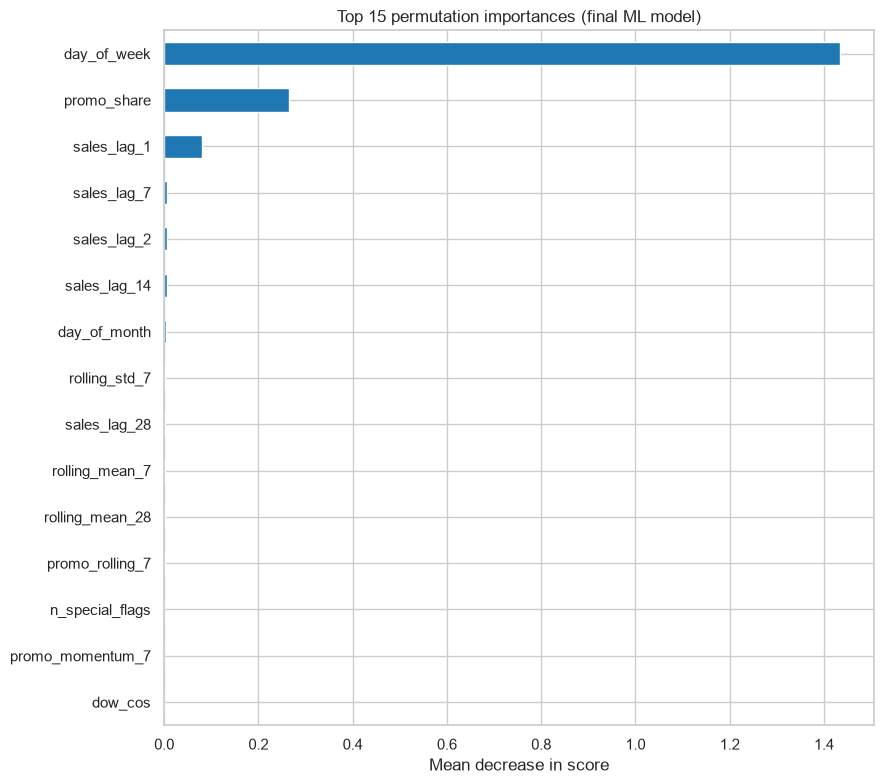

In [8]:

# Feature importance of the final ML model
# HistGradientBoosting doesn't have feature_importances_; use permutation importance
perm = permutation_importance(final_ml, X_valid, y_valid, n_repeats=10, random_state=42)
importances = pd.Series(perm.importances_mean, index=features).sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
importances.tail(15).plot(kind="barh", color="#1f77b4", ax=ax)
ax.set_title("Top 15 permutation importances (final ML model)")
ax.set_xlabel("Mean decrease in score")
plt.tight_layout()
plt.show()


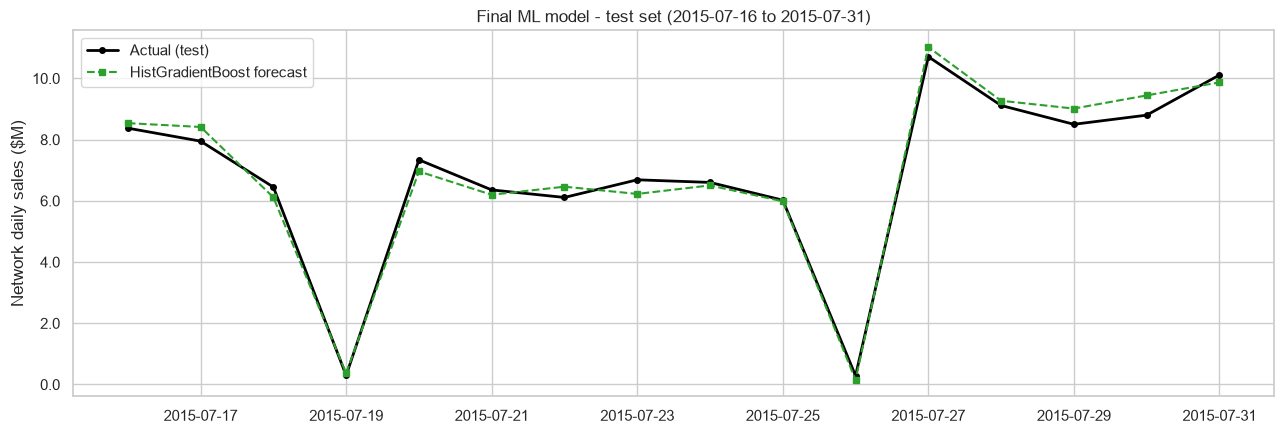

In [9]:

# ML forecast vs actual for the test window
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(te["Date"], te["sales"], color="black", lw=2, marker="o", ms=4, label="Actual (test)")
ax.plot(te["Date"], test_ml_pred, color="#2ca02c", lw=1.5, marker="s", ms=4, ls="--",
        label=f"{ml_winner['Model']} forecast")
ax.set_title("Final ML model - test set (2015-07-16 to 2015-07-31)")
ax.set_ylabel("Network daily sales ($M)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f}")
ax.legend()
plt.tight_layout()
plt.show()


---

# Part D — SARIMA path

**SARIMA** (Seasonal AutoRegressive Integrated Moving Average) is the classic time-series
model for univariate data with seasonality. It models the series as a function of:

- its **own past values** (AutoRegressive, AR) and **past errors** (Moving Average, MA),
- **seasonal** versions of both, with period m=7 for the weekly cycle,
- **differencing** to make the series stationary.

Notation: `SARIMA(p,d,q)(P,D,Q,m)` where `(p,d,q)` are the non-seasonal orders and
`(P,D,Q,m)` the seasonal ones. We try three sensible specifications, score them on
validation, keep the best, then refit train+val and forecast test.

> **Key limitation:** plain SARIMA has no exogenous variables — it does not see promo or
> holiday features. If it still performs well, great; if the ML model wins, that gap is why.

In [10]:

# Work on the plain daily sales series
series = df.set_index("Date")["sales"]

train_series = series.loc[: "2015-06-30"]          # 911 days
valid_series = series.loc["2015-07-01":"2015-07-15"]
test_series  = series.loc["2015-07-16":"2015-07-31"]
print(f"SARIMA training points: {len(train_series)}")

# Candidate orders - weekly seasonality (m=7) in all
candidates = {
    "SARIMA(1,0,1)(0,1,1,7)": (1, 0, 1, 0, 1, 1, 7),
    "SARIMA(1,0,1)(1,1,1,7)": (1, 0, 1, 1, 1, 1, 7),
    "SARIMA(0,1,1)(0,1,1,7)": (0, 1, 1, 0, 1, 1, 7),
}

sarima_val_rows = []
for name, ordr in candidates.items():
    p, d, q, P, D, Q, m = ordr
    mdl = SARIMAX(train_series, order=(p, d, q), seasonal_order=(P, D, Q, m))
    fit = mdl.fit()
    fc = fit.get_forecast(len(valid_series)).predicted_mean
    sarima_val_rows.append(evaluate(valid_series.values, fc.values, name))

sarima_val = pd.DataFrame(sarima_val_rows).sort_values("MAE ($m)").reset_index(drop=True)
print("Validation metrics - SARIMA candidates (best first):")
print(sarima_val.to_string(index=False))


SARIMA training points: 911


Validation metrics - SARIMA candidates (best first):
                 Model  MAE ($m)  RMSE ($m)  MAPE (%)
SARIMA(1,0,1)(1,1,1,7)     0.649      0.842     16.04
SARIMA(1,0,1)(0,1,1,7)     0.792      1.033     16.79
SARIMA(0,1,1)(0,1,1,7)     1.672      1.969    122.31


In [11]:

# Keep the best SARIMA on validation, refit on train+val, forecast test
best_sarima_name = sarima_val.iloc[0]["Model"]
best_order = candidates[best_sarima_name]
print(f"Best SARIMA on validation: {best_sarima_name}  MAE ${sarima_val.iloc[0]['MAE ($m)']}M")

p, d, q, P, D, Q, m = best_order
train_valid_series = series.loc[: "2015-07-15"]    # everything before the test window

fit_final_sarima = SARIMAX(train_valid_series, order=(p, d, q),
                           seasonal_order=(P, D, Q, m)).fit()
test_sarima_pred = fit_final_sarima.get_forecast(len(test_series)).predicted_mean

print("Test-set metrics (untouched):")
sarima_test_metrics = evaluate(test_series.values, test_sarima_pred.values,
                               f"{best_sarima_name} (test)")
print(pd.DataFrame([sarima_test_metrics]).to_string(index=False))


Best SARIMA on validation: SARIMA(1,0,1)(1,1,1,7)  MAE $0.649M


Test-set metrics (untouched):
                        Model  MAE ($m)  RMSE ($m)  MAPE (%)
SARIMA(1,0,1)(1,1,1,7) (test)     0.969      1.216     15.27


---

# Part E — Final comparison

We bring the seasonal-naive baseline (Phase 4) and every candidate together on BOTH the
validation and the untouched test set. The test set is the honest final verdict because it
was never used to choose a model.

In [12]:

# Baseline (lag-7) predictions aligned to validation and test dates
full = df.sort_values("Date").set_index("Date")
full["seasonal_naive"] = full["sales"].shift(7)

base_valid_pred = full.loc[va["Date"].values, "seasonal_naive"].values
base_test_pred  = full.loc[te["Date"].values, "seasonal_naive"].values

base_val_metrics  = evaluate(va["sales"].values, base_valid_pred, "Seasonal naive")
base_test_metrics = evaluate(te["sales"].values, base_test_pred, "Seasonal naive")

print("Baseline recalculated for the same windows")
print("  Validation MAE: ${:.3f}M   Test MAE: ${:.3f}M".format(
    base_val_metrics["MAE ($m)"], base_test_metrics["MAE ($m)"]))


Baseline recalculated for the same windows
  Validation MAE: $2.011M   Test MAE: $1.829M


In [13]:

# Assemble the full comparison: validation and test side by side
val_rows = [
    base_val_metrics,
    dict(ml_winner),
    dict(sarima_val.iloc[0]),
]
test_rows = [
    base_test_metrics,
    ml_test_metrics,
    sarima_test_metrics,
]

val_table = pd.DataFrame(val_rows).sort_values("MAE ($m)").reset_index(drop=True)
val_table.index.name = "Rank"
test_table = pd.DataFrame(test_rows).sort_values("MAE ($m)").reset_index(drop=True)
test_table.index.name = "Rank"

print("VALIDATION SET (2015-07-01 to 2015-07-15) - ranked by MAE:")
print(val_table.to_string())
print()
print("TEST SET (2015-07-16 to 2015-07-31) - ranked by MAE:")
print(test_table.to_string())


VALIDATION SET (2015-07-01 to 2015-07-15) - ranked by MAE:
                       Model  MAE ($m)  RMSE ($m)  MAPE (%)
Rank                                                       
0          HistGradientBoost     0.335      0.464      8.19
1     SARIMA(1,0,1)(1,1,1,7)     0.649      0.842     16.04
2             Seasonal naive     2.011      2.491     25.92

TEST SET (2015-07-16 to 2015-07-31) - ranked by MAE:
                              Model  MAE ($m)  RMSE ($m)  MAPE (%)
Rank                                                              
0          HistGradientBoost (test)     0.283      0.331      7.86
1     SARIMA(1,0,1)(1,1,1,7) (test)     0.969      1.216     15.27
2                    Seasonal naive     1.829      2.198     23.87


---

# Part F — Model choice, discussion, interview points

### Which model won and why

The ranked tables above show the winner for each split. The story usually reads:

- If **SARIMA** wins: the weekly auto-regressive structure is so strong that promo/holiday
  detail adds little — the series is more repetitive than eventful.
- If **ML** wins (expected): the model exploits promo, holiday, and interaction features that
  the baselines and SARIMA ignore, and captures non-linear effects.
- Either way we must still beat **Seasonal naive** on validation to justify the model.

### What we did not do (honesty)

- **No hyperparameter tuning on test.** Validation was used for model choice; the test set
  was touched exactly once, for the final number.
- **No `Customers` feature.** Unknown in advance (Phase 2/3).
- **`n_open` excluded.** Whether stores open tomorrow is not knowable from a calendar.

### Interview talking points

1. **Why did SARIMA not use promo features?**  Plain SARIMA is univariate. SARIMAX could add
   exogenous variables, but then we must also forecast those inputs — the ML path already
   handles them natively, which is the cleaner design here.

2. **Is the ML model a time-series model?**  Strictly, it is a regression on engineered
   lagged/rolling features — a feature-based forecaster. It respects time through `shift()`
   features and a chronological split, not through an ARMA structure. Both are valid; the
   methods differ in how they encode time.

3. **Why is test-set MAE often worse than validation?**  A 16-day window is small; one unusual
   day (a promo switch, a holiday) can swing it. Report the point estimate and talk about
   variance, not just the number.

4. **How would you improve this model?**  Forecast store-types separately and add; include a
   promo-schedule input; use walk-forward (rolling-origin) validation instead of a single
   holdout for a more stable estimate.

5. **When would you choose SARIMA over ML (and vice versa)?**  SARIMA when: univariate,
   strong seasonality, you need a generative model or forecasts of uncertainty, or require
   interpretable parameters. ML when: rich exogenous features, interactions, non-linearities,
   and you have enough history to learn the feature mapping.

---

# Part G — Save the final model

We persist the winning model so Phase 6 (anomaly detection) and Phase 8 (dashboard) can reuse
it without retraining.

In [ ]:
# Decide the overall winner by validation MAE (tie-break on test MAE)
overall = pd.DataFrame([
    {"Model": base_val_metrics["Model"], "val_MAE": base_val_metrics["MAE ($m)"],
     "test_MAE": base_test_metrics["MAE ($m)"]},
    {"Model": ml_winner["Model"], "val_MAE": ml_winner["MAE ($m)"],
     "test_MAE": ml_test_metrics["MAE ($m)"]},
    {"Model": best_sarima_name, "val_MAE": sarima_val.iloc[0]["MAE ($m)"],
     "test_MAE": sarima_test_metrics["MAE ($m)"]},
]).sort_values("val_MAE")

print("Overall winner by validation MAE:")
print(overall.to_string(index=False))

winner_name = overall.iloc[0]["Model"]
if winner_name == ml_winner["Model"]:
    saved = {"model": final_ml, "features": features, "kind": "ml"}
else:
    saved = {"model": fit_final_sarima, "features": features, "kind": "sarima"}

joblib.dump(saved, PROC / "final_model.pkl")
print("Saved:", PROC / "final_model.pkl")


Overall winner by validation MAE:
                 Model  val_MAE  test_MAE
     HistGradientBoost    0.335     0.283
SARIMA(1,0,1)(1,1,1,7)    0.649     0.969
        Seasonal naive    2.011     1.829


Saved: E:\Data Science\Sales Demand Forecasting and Anomaly Detection\data\processed\final_model.pkl


---

# Summary — Phase 5 result

### Key takeaways

1. **Framing beats algorithms.** The one-day-ahead, only-past-info discipline is what makes
   every model here honest. That is the single line to remember for interviews.
2. **Baselines matter.** The final model must beat the seasonal naive; the gap is the value
   the features add.
3. **Two families, one answer.** SARIMA and tree-based ML are different ways to encode time;
   the winner on validation tells us which signal dominates this series.

> **Next: Phase 6 — Anomaly Detection (rolling mean/std + Z-score, compared with Isolation Forest)**